# FoodVision AI — Food-11 Classification Using CNN

## מטרת הפרויקט
פיתוח מערכת לסיווג תמונות מזון ל־11 קטגוריות באמצעות CNN,
ושילוב המודל הנבחר באתר המבוסס על FastAPI.

## תהליך העבודה
1. טעינת מאגר Food-11 ובדיקת התמונות והקטגוריות.
2. הכנת התמונות וחלוקתן לקבוצות הקיימות במאגר.
3. בנייה ואימון של Baseline CNN ושל Improved CNN מאפס.
4. השוואת המודלים ובחירת מודל לפי Validation.
5. בדיקה סופית על Evaluation והצגת מטריצת בלבול.
6. חיזוי לתמונות ושמירת קובצי המודל והגדרותיו.

קבוצת Evaluation אינה משמשת לבחירת המודל או לכוונון שלו.

In [1]:
import json
import random
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout,
    RandomFlip, RandomRotation, RandomZoom
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint,
    CSVLogger, ReduceLROnPlateau
)

In [2]:
SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 30

tf.keras.utils.set_random_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image size: (128, 128)
Batch size: 32
Maximum epochs: 30


In [3]:
from google.colab import drive

drive.mount("/content/drive")

project_dir = Path("/content/drive/MyDrive/FoodVision-AI-11")
zip_path = project_dir / "Food-11.zip"

if not zip_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {zip_path}")

run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
run_dir = project_dir / "runs" / run_id
run_dir.mkdir(parents=True, exist_ok=False)

print("Dataset:", zip_path)
print("Results folder:", run_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/drive/MyDrive/FoodVision-AI-11/Food-11.zip
Results folder: /content/drive/MyDrive/FoodVision-AI-11/runs/20261024_081420_538652


In [4]:
extract_dir = Path("/content/foodvision_data")
split_names = ("training", "validation", "evaluation")

def find_dataset_root(root):
    if not root.exists():
        return None

    candidates = [root]
    candidates.extend(p for p in root.rglob("*") if p.is_dir())

    return next(
        (p for p in candidates
            if all((p / name).is_dir() for name in split_names)),None)

data_root = find_dataset_root(extract_dir)

if data_root is None:
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path) as archive:
        resolved_root = extract_dir.resolve()

        for member in archive.infolist():
            destination = (extract_dir / member.filename).resolve()

            if not destination.is_relative_to(resolved_root):
                raise ValueError("Invalid archive path")

        archive.extractall(extract_dir)

    data_root = find_dataset_root(extract_dir)

if data_root is None:
    raise FileNotFoundError("Dataset split folders were not found")

train_dir = data_root / "training"
val_dir = data_root / "validation"
test_dir = data_root / "evaluation"

print("Dataset root:", data_root)

Dataset root: /content/foodvision_data


In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

class_names = sorted(
    p.name for p in train_dir.iterdir()
    if p.is_dir() and not p.name.startswith(".")
)

assert len(class_names) == 11, (
    f"Expected 11 classes, found {len(class_names)}"
)

def image_paths(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

rows = []
invalid_images = []

for split_name in split_names:
    split_path = data_root / split_name

    split_classes = sorted(
        p.name for p in split_path.iterdir()
        if p.is_dir() and not p.name.startswith(".")
    )
    assert split_classes == class_names, (
        f"Class mismatch in {split_name}"
    )

    for class_name in class_names:
        paths = image_paths(split_path / class_name)
        assert paths, f"No images: {split_name}/{class_name}"

        rows.append({
            "Split": split_name,
            "Class": class_name,
            "Images": len(paths)
        })

        for path in paths:
            try:
                with Image.open(path) as image:
                    image.verify()
            except Exception as exc:
                invalid_images.append((str(path), str(exc)))

if invalid_images:
    print(pd.DataFrame(
        invalid_images, columns=["File", "Error"]
    ).to_string(index=False))
    raise ValueError("Fix invalid images before continuing")

dataset_counts = pd.DataFrame(rows)

display(
    dataset_counts.pivot(
        index="Class", columns="Split", values="Images"
    )
)
display(dataset_counts.groupby("Split")["Images"].sum())

print("Total images:", dataset_counts["Images"].sum())
print("\nClass order:")
for index, name in enumerate(class_names):
    print(f"{index:02d}. {name}")

dataset_counts.to_csv(
    run_dir / "dataset_counts.csv", index=False
)

Split,evaluation,training,validation
Class,,,
Bread,368,994,362
Dairy product,148,429,144
Dessert,500,1500,500
Egg,335,986,327
Fried food,287,848,326
Meat,432,1325,449
Noodles-Pasta,147,440,147
Rice,96,280,96
Seafood,303,855,347


,Images
Split,
evaluation,3347
training,9866
validation,3430


Total images: 16643

Class order:
00. Bread
01. Dairy product
02. Dessert
03. Egg
04. Fried food
05. Meat
06. Noodles-Pasta
07. Rice
08. Seafood
09. Soup
10. Vegetable-Fruit


In [6]:
rng = random.Random(SEED)

fig, axes = plt.subplots(3, 4, figsize=(15, 11))
axes = axes.ravel()

for index, class_name in enumerate(class_names):
    path = rng.choice(image_paths(train_dir / class_name))

    with Image.open(path) as image:
        axes[index].imshow(image.convert("RGB"))

    axes[index].set_title(class_name)
    axes[index].axis("off")

for axis in axes[len(class_names):]:
    axis.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "dataset_examples.png", dpi=160)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [7]:
def load_dataset(folder, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        folder,
        labels="inferred",
        label_mode="int",
        class_names=class_names,
        color_mode="rgb",
        image_size=IMG_SIZE,
        interpolation="bilinear",
        crop_to_aspect_ratio=False,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

def normalize_images(images, labels):
    return tf.cast(images, tf.float32) / 255.0, labels

def prepare_dataset(dataset):
    return dataset.map(
        normalize_images,
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)

train_ds = prepare_dataset(load_dataset(train_dir, True))
val_ds = prepare_dataset(load_dataset(val_dir, False))
test_ds = prepare_dataset(load_dataset(test_dir, False))

for images, labels in train_ds.take(1):
    print("Images:", images.shape)
    print("Labels:", labels.shape)
    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        float(tf.reduce_max(images))
    )

Found 9866 files belonging to 11 classes.
Found 3430 files belonging to 11 classes.
Found 3347 files belonging to 11 classes.
Images: (32, 128, 128, 3)
Labels: (32,)
Pixel range: 0.0 1.0


In [8]:
def build_baseline():
    model = Sequential([
        Input(shape=(*IMG_SIZE, 3)),

        Conv2D(32, 3, padding="same", activation="relu"),
        MaxPooling2D(),

        Conv2D(64, 3, padding="same", activation="relu"),
        MaxPooling2D(),

        Conv2D(128, 3, padding="same", activation="relu"),
        MaxPooling2D(),

        GlobalAveragePooling2D(),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(len(class_names), activation="softmax")
    ], name="FoodVision_Baseline_11")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [9]:
def build_improved():
    augmentation = Sequential([
        RandomFlip("horizontal", seed=SEED),
        RandomRotation(0.05, seed=SEED + 1),
        RandomZoom(0.1, seed=SEED + 2)
    ], name="Data_Augmentation")

    model = Sequential([
        Input(shape=(*IMG_SIZE, 3)),
        augmentation,

        Conv2D(32, 3, padding="same", activation="relu"),
        BatchNormalization(),
        Conv2D(32, 3, padding="same", activation="relu"),
        MaxPooling2D(),

        Conv2D(64, 3, padding="same", activation="relu"),
        BatchNormalization(),
        Conv2D(64, 3, padding="same", activation="relu"),
        MaxPooling2D(),

        Conv2D(128, 3, padding="same", activation="relu"),
        BatchNormalization(),
        Conv2D(128, 3, padding="same", activation="relu"),
        MaxPooling2D(),

        Conv2D(256, 3, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling2D(),

        GlobalAveragePooling2D(),
        Dense(256, activation="relu"),
        Dropout(0.4),
        Dense(len(class_names), activation="softmax")
    ], name="FoodVision_Improved_11")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.0005),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [10]:
baseline_model = build_baseline()
improved_model = build_improved()

baseline_model.summary()
improved_model.summary()

Model: "FoodVision_Baseline_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,179 (434.29 KB)

 Trainable params: 111,179 (434.29 KB)

 Non-trainable params: 0 (0.00 B)

Model: "FoodVision_Improved_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_Augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │         2,827 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,715 (2.49 MB)

 Trainable params: 651,755 (2.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [11]:
if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError(
        "GPU is unavailable. Enable a GPU runtime before training."
    )

# הגדרת פעולות לניהול האימון
def make_callbacks(model_name, patience, reduce_lr=False):

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=patience,
            restore_best_weights=True,
            verbose=0
        ),

        ModelCheckpoint(
            filepath=str(run_dir / f"{model_name}.keras"),
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        ),

        CSVLogger(
            filename=str(run_dir / f"{model_name}_history.csv"),
            append=False
        )
    ]

    if reduce_lr:
        callbacks.append(
            ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=3,
                min_lr=0.00001,
                verbose=0
            )
        )

    return callbacks

In [12]:
# אימון מודל Baseline CNN
baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=make_callbacks(
        "foodvision11_baseline",
        patience=5
    ),
    verbose=1
)

Epoch 1/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 38s 99ms/step - accuracy: 0.2066 - loss: 2.1973 - val_accuracy: 0.2741 - val_loss: 2.0519
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.2748 - loss: 2.0395 - val_accuracy: 0.3003 - val_loss: 2.0125
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.3028 - loss: 1.9721 - val_accuracy: 0.3306 - val_loss: 1.9128
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.3344 - loss: 1.8961 - val_accuracy: 0.3566 - val_loss: 1.8212
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.3691 - loss: 1.8024 - val_accuracy: 0.3752 - val_loss: 1.7333
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.3942 - loss: 1.7403 - val_accuracy: 0.4073 - val_loss: 1.6895
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.4132 - loss: 1.6841 - val_accuracy: 0.4047 - val_loss: 1.7158
Epoch 8/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.4388 - loss: 1.6212 - 

In [13]:
# אימון מודל Improved CNN
improved_history = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=make_callbacks(
        "foodvision11_improved",
        patience=7,
        reduce_lr=True
    ),
    verbose=1
)

Epoch 1/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 42s 102ms/step - accuracy: 0.2882 - loss: 2.0378 - val_accuracy: 0.1490 - val_loss: 4.8975 - learning_rate: 5.0000e-04
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 33s 97ms/step - accuracy: 0.3942 - loss: 1.7497 - val_accuracy: 0.3691 - val_loss: 1.8488 - learning_rate: 5.0000e-04
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.4597 - loss: 1.5743 - val_accuracy: 0.4122 - val_loss: 1.8724 - learning_rate: 5.0000e-04
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 30s 97ms/step - accuracy: 0.5167 - loss: 1.4347 - val_accuracy: 0.3312 - val_loss: 2.7948 - learning_rate: 5.0000e-04
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 30s 97ms/step - accuracy: 0.5541 - loss: 1.3199 - val_accuracy: 0.4516 - val_loss: 1.9412 - learning_rate: 5.0000e-04
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 34s 111ms/step - accuracy: 0.6100 - loss: 1.1544 - val_accuracy: 0.4484 - val_loss: 1.7983 - learning_rate: 2.5000e-04
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 30s 97ms/s

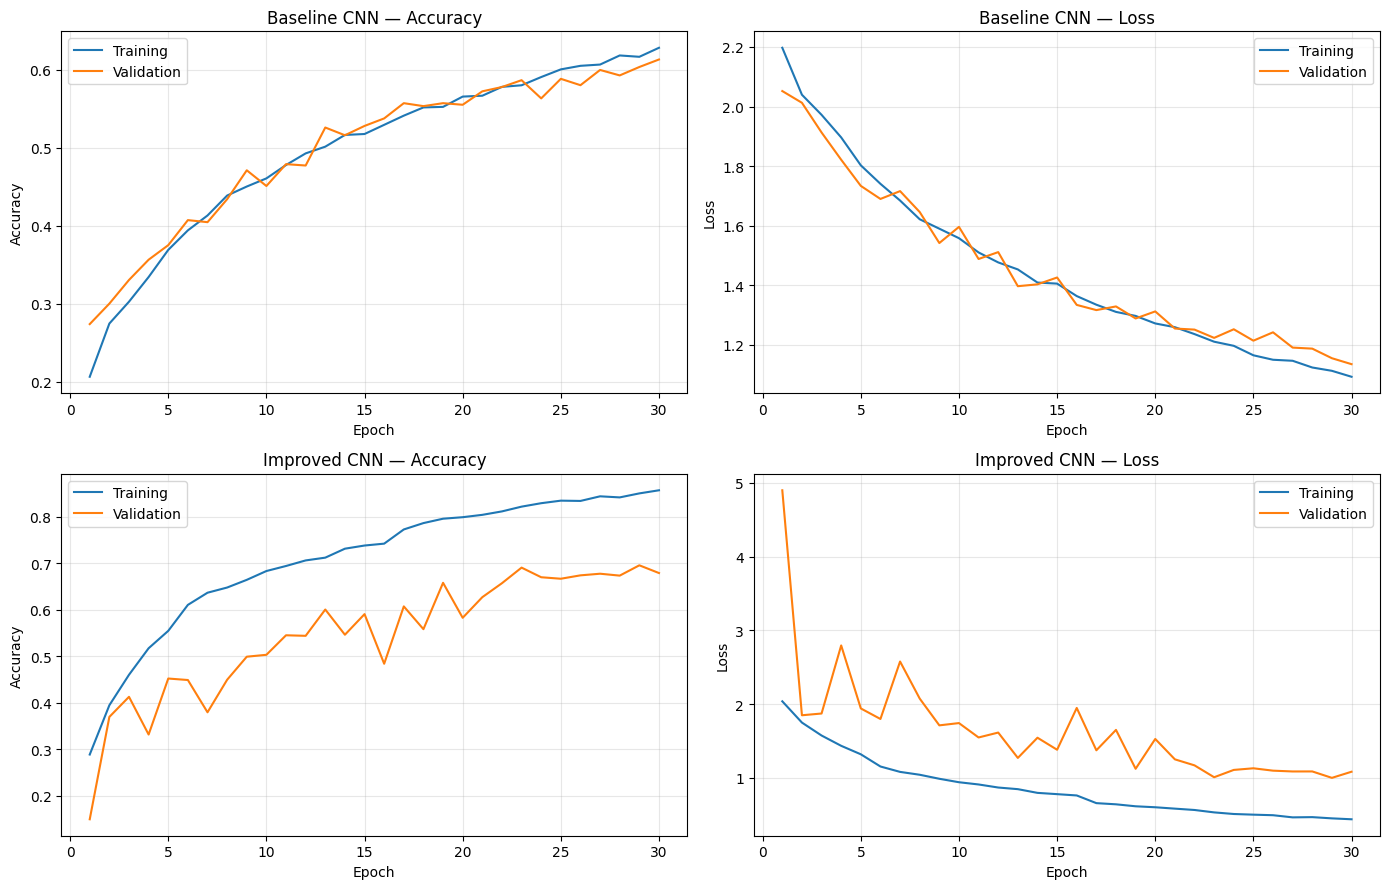

In [14]:
history_tables = {
    "Baseline CNN": pd.read_csv(
        run_dir / "foodvision11_baseline_history.csv"
    ),
    "Improved CNN": pd.read_csv(
        run_dir / "foodvision11_improved_history.csv"
    )
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, (name, history) in enumerate(history_tables.items()):
    epochs = history["epoch"] + 1

    axes[row, 0].plot(
        epochs, history["accuracy"], label="Training"
    )
    axes[row, 0].plot(
        epochs, history["val_accuracy"], label="Validation"
    )
    axes[row, 0].set_title(f"{name} — Accuracy")
    axes[row, 0].set_ylabel("Accuracy")

    axes[row, 1].plot(
        epochs, history["loss"], label="Training"
    )
    axes[row, 1].plot(
        epochs, history["val_loss"], label="Validation"
    )
    axes[row, 1].set_title(f"{name} — Loss")
    axes[row, 1].set_ylabel("Loss")

    for axis in axes[row]:
        axis.set_xlabel("Epoch")
        axis.legend()
        axis.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(run_dir / "training_curves.png", dpi=180)
plt.show()

In [15]:
candidates = {
    "Baseline CNN": tf.keras.models.load_model(
        run_dir / "foodvision11_baseline.keras"
    ),
    "Improved CNN": tf.keras.models.load_model(
        run_dir / "foodvision11_improved.keras"
    )
}

comparison_rows = []

for name, model in candidates.items():
    metrics = model.evaluate(
        val_ds, verbose=0, return_dict=True
    )

    comparison_rows.append({
        "Model": name,
        "Validation Accuracy": float(metrics["accuracy"]),
        "Validation Loss": float(metrics["loss"])
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    ["Validation Accuracy", "Validation Loss"],
    ascending=[False, True]
).reset_index(drop=True)

selected_model_name = comparison.loc[0, "Model"]
selected_model = candidates[selected_model_name]

display(comparison)
print("Selected model:", selected_model_name)

comparison.to_csv(
    run_dir / "validation_comparison.csv", index=False
)

,Model,Validation Accuracy,Validation Loss
0,Improved CNN,0.695044,1.000506
1,Baseline CNN,0.613120,1.134415


Selected model: Improved CNN


Selected model: Improved CNN
Evaluation images: 3347
Evaluation accuracy: 72.06%
Evaluation loss: 0.9062


,precision,recall,f1-score,support
Bread,0.720000,0.489130,0.582524,368.000000
Dairy product,0.714286,0.540541,0.615385,148.000000
Dessert,0.575221,0.650000,0.610329,500.000000
Egg,0.825000,0.689552,0.751220,335.000000
Fried food,0.862069,0.609756,0.714286,287.000000
Meat,0.659011,0.863426,0.747495,432.000000
Noodles-Pasta,0.740506,0.795918,0.767213,147.000000
Rice,0.710280,0.791667,0.748768,96.000000
Seafood,0.818182,0.623762,0.707865,303.000000
Soup,0.908903,0.878000,0.893184,500.000000


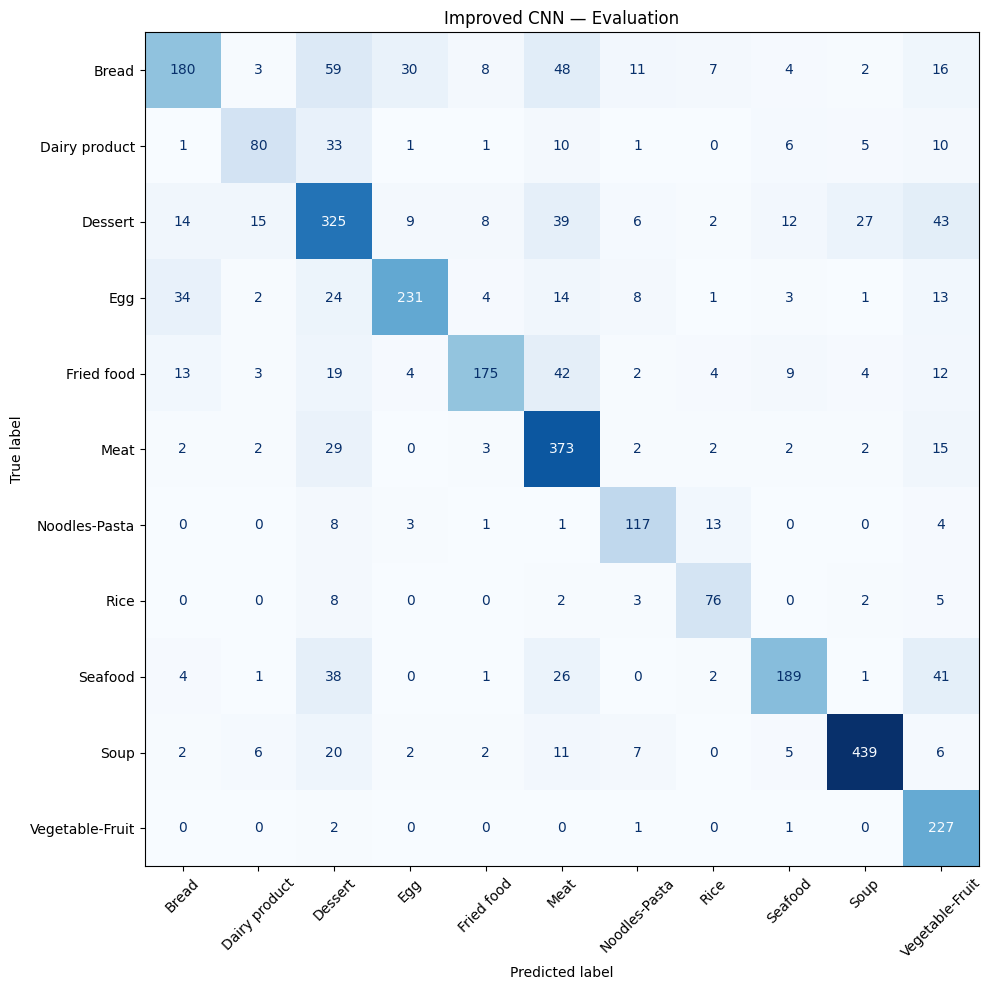

In [16]:
evaluation = selected_model.evaluate(
    test_ds, verbose=0, return_dict=True
)

true_labels = []
all_probabilities = []

for images, labels in test_ds:
    probabilities = selected_model(
        images, training=False
    ).numpy()

    true_labels.append(labels.numpy())
    all_probabilities.append(probabilities)

y_true = np.concatenate(true_labels)
test_probabilities = np.concatenate(all_probabilities)
y_pred = np.argmax(test_probabilities, axis=1)

label_indices = np.arange(len(class_names))

report = classification_report(
    y_true,
    y_pred,
    labels=label_indices,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_table = pd.DataFrame(report).transpose()

print("Selected model:", selected_model_name)
print(f"Evaluation images: {len(y_true)}")
print(f"Evaluation accuracy: {evaluation['accuracy']:.2%}")
print(f"Evaluation loss: {evaluation['loss']:.4f}")
display(report_table)

matrix = confusion_matrix(
    y_true, y_pred, labels=label_indices
)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title(f"{selected_model_name} — Evaluation")
plt.tight_layout()
plt.savefig(run_dir / "confusion_matrix.png", dpi=180)
plt.show()

evaluation_results = {
    "selected_model": selected_model_name,
    "images": int(len(y_true)),
    "accuracy": float(evaluation["accuracy"]),
    "loss": float(evaluation["loss"]),
    "macro_f1": float(report["macro avg"]["f1-score"])
}

(run_dir / "evaluation_metrics.json").write_text(
    json.dumps(evaluation_results, indent=2),
    encoding="utf-8"
)

report_table.to_csv(run_dir / "classification_report.csv")

np.savez_compressed(
    run_dir / "evaluation_predictions.npz",
    y_true=y_true,
    probabilities=test_probabilities
)

In [17]:
def preprocess_image_file(path):
    image_bytes = tf.io.read_file(str(path))

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE,
        method="bilinear",
        antialias=False
    )

    return tf.cast(image, tf.float32) / 255.0

Single-image prediction
True class: Soup
Predicted class: Soup
Confidence: 99.45%


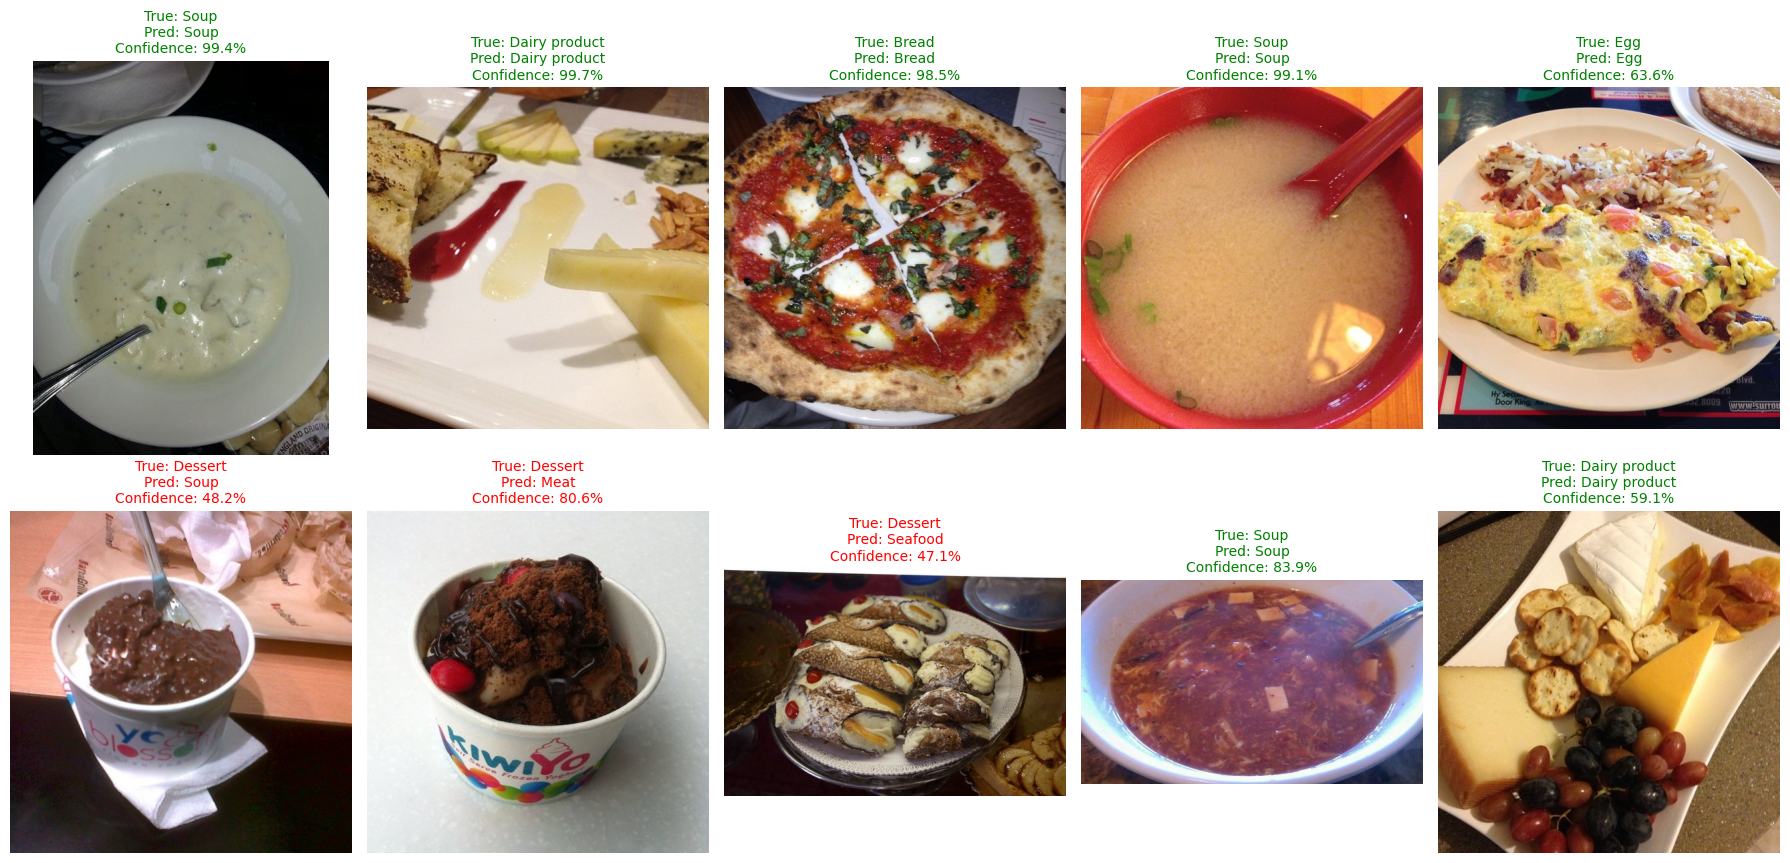

Correct in this illustration: 7/10
Overall performance is reported on the full Evaluation set.


In [18]:
all_test_images = sorted(
    path
    for class_name in class_names
    for path in image_paths(test_dir / class_name)
)

rng = random.Random(SEED)
selected_paths = rng.sample(all_test_images, min(10, len(all_test_images)))

# חיזוי לתמונה בודדת
single_path = selected_paths[0]
single_batch = tf.expand_dims(
    preprocess_image_file(single_path), axis=0
)

single_scores = selected_model.predict(
    single_batch, verbose=0
)[0]
single_index = int(np.argmax(single_scores))

print("Single-image prediction")
print("True class:", single_path.parent.name)
print("Predicted class:", class_names[single_index])
print(f"Confidence: {single_scores[single_index]:.2%}")

# חיזוי לעשר תמונות להמחשה
batch = tf.stack([
    preprocess_image_file(path)
    for path in selected_paths
])

sample_scores = selected_model.predict(batch, verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(18, 9))
correct = 0

for axis, path, scores in zip(
    axes.ravel(), selected_paths, sample_scores
):
    index = int(np.argmax(scores))
    predicted_class = class_names[index]
    true_class = path.parent.name
    is_correct = predicted_class == true_class
    correct += int(is_correct)

    with Image.open(path) as image:
        axis.imshow(image.convert("RGB"))

    axis.set_title(
        f"True: {true_class}\n"
        f"Pred: {predicted_class}\n"
        f"Confidence: {scores[index]:.1%}",
        color="green" if is_correct else "red",
        fontsize=10
    )
    axis.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "prediction_examples.png", dpi=180)
plt.show()

print(f"Correct in this illustration: {correct}/10")
print("Overall performance is reported on the full Evaluation set.")

In [19]:
export_dir = run_dir / "export"
export_dir.mkdir(parents=True, exist_ok=True)

final_model_path = export_dir / "foodvision.keras"
selected_model.save(final_model_path)

(export_dir / "class_names.json").write_text(
    json.dumps(class_names, ensure_ascii=False, indent=4),
    encoding="utf-8"
)

preprocessing_config = {
    "image_size": list(IMG_SIZE),
    "color_mode": "rgb",
    "resize_backend": "tensorflow",
    "interpolation": "bilinear",
    "antialias": False,
    "preserve_aspect_ratio": False,
    "normalization": "divide_by_255",
    "input_range": [0.0, 1.0],
    "class_names": class_names,
    "unknown_threshold": 0.60,
    "unknown_threshold_note": (
        "Assignment rule; not calibrated as an out-of-distribution detector"
    )
}

(export_dir / "preprocessing.json").write_text(
    json.dumps(
        preprocessing_config, ensure_ascii=False, indent=4
    ),
    encoding="utf-8"
)

673

In [20]:
# בדיקת טעינה חוזרת והתאמת תחזיות
reloaded_model = tf.keras.models.load_model(
    final_model_path, compile=False
)

check_batch = next(iter(test_ds))[0][:4]

before_save = selected_model(
    check_batch, training=False
).numpy()
after_load = reloaded_model(
    check_batch, training=False
).numpy()

np.testing.assert_allclose(
    before_save, after_load,
    rtol=1e-5, atol=1e-6
)

print("Export verified.")
print("Selected model:", selected_model_name)
print("Export folder:", export_dir)

for path in sorted(export_dir.iterdir()):
    print(path.name)

Export verified.
Selected model: Improved CNN
Export folder: /content/drive/MyDrive/FoodVision-AI-11/runs/20261024_081420_538652/export
class_names.json
foodvision.keras
preprocessing.json


סיכום ומסקנות
בפרויקט נבנו ואומנו מאפס שני מודלי CNN לסיווג 11 קטגוריות מזון.

המודל המשופר כולל Data Augmentation, שכבות קונבולוציה נוספות,
Batch Normalization ו־Dropout. נבדקה תרומת השינויים באמצעות
השוואה למודל הבסיסי על קבוצת Validation.

המודל הסופי נבחר לפי Validation בלבד. ביצועיו הסופיים מוצגים
בתוצאות Evaluation, בדוח המדדים לכל קטגוריה ובמטריצת הבלבול.

גרפי האימון מאפשרים לבחון את התקדמות הלמידה ואת הפער בין
ביצועי האימון לביצועי האימות. דוגמאות החיזוי ממחישות הצלחות
וטעויות ואינן מחליפות את ההערכה על קבוצת הבדיקה המלאה.

המודל הנבחר נשמר לצד סדר הקטגוריות והגדרות עיבוד התמונה.
בעת שילובו באתר יש להשתמש באותן הגדרות עיבוד בדיוק.

ערך Softmax מוצג כציון ביטחון של המודל; הוא אינו הבטחה לנכונות.
סף Unknown של 60% אינו מבטיח זיהוי של תמונות שאינן מזון.